In [1]:
# Cell 1: Upload file kaggle.json
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"quanganhleee","key":"5f3cc45c02e7f029f90cb403ab880d75"}'}

In [2]:
# Cell 2: Cài đặt thư mục cấu hình Kaggle và tải dataset
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Tải dataset (ASL Alphabet)
!kaggle datasets download -d grassknoted/asl-alphabet

# Giải nén dataset
!unzip -q asl-alphabet.zip -d asl_data
print("Giải nén hoàn tất!")

Dataset URL: https://www.kaggle.com/datasets/grassknoted/asl-alphabet
License(s): GPL-2.0
100% 1.03G/1.03G [00:48<00:00, 22.5MB/s]

Giải nén hoàn tất!


In [3]:
# Cell 3: Đọc và tiền xử lý dữ liệu
import os
import random
import shutil
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Thiết lập đường dẫn dữ liệu gốc
data_dir = "asl_data/asl_alphabet_train/asl_alphabet_train"
classes = sorted(os.listdir(data_dir))

# Tạo thư mục lưu trữ dữ liệu rút gọn
split_dir = "asl_split"
train_dir = os.path.join(split_dir, "train")
val_dir = os.path.join(split_dir, "val")
test_dir = os.path.join(split_dir, "test")

for folder in [train_dir, val_dir, test_dir]:
    os.makedirs(folder, exist_ok=True)
    for c in classes:
        os.makedirs(os.path.join(folder, c), exist_ok=True)

# Lọc và copy 15% ảnh ngẫu nhiên từ mỗi class
IMAGE_SIZE = (100, 100)
sample_ratio = 1  # Lấy 15% dữ liệu

print("Đang phân chia tập dữ liệu...")
for c in classes:
    class_path = os.path.join(data_dir, c)
    images = os.listdir(class_path)
    # Lấy ngẫu nhiên
    num_samples = int(len(images) * sample_ratio)
    sampled_images = random.sample(images, num_samples)

    # Chia tỉ lệ: 80% Train, 10% Val, 10% Test
    train_idx = int(num_samples * 0.8)
    val_idx = int(num_samples * 0.9)

    train_imgs = sampled_images[:train_idx]
    val_imgs = sampled_images[train_idx:val_idx]
    test_imgs = sampled_images[val_idx:]

    # Copy sang các thư mục tương ứng
    for img in train_imgs:
        shutil.copy(os.path.join(class_path, img), os.path.join(train_dir, c, img))
    for img in val_imgs:
        shutil.copy(os.path.join(class_path, img), os.path.join(val_dir, c, img))
    for img in test_imgs:
        shutil.copy(os.path.join(class_path, img), os.path.join(test_dir, c, img))

print("Phân chia dữ liệu hoàn thành!")

Đang phân chia tập dữ liệu...
Phân chia dữ liệu hoàn thành!


In [4]:
# Cell 4: Tạo Data Loader
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Base generator (chỉ chuẩn hóa giá trị pixel về [0, 1])
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=IMAGE_SIZE, batch_size=32, class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir, target_size=IMAGE_SIZE, batch_size=32, class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir, target_size=IMAGE_SIZE, batch_size=32, class_mode='categorical', shuffle=False
)

Found 69600 images belonging to 29 classes.
Found 8700 images belonging to 29 classes.
Found 8700 images belonging to 29 classes.


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

def build_base_model():
    model = Sequential([
        # Khối CNN 1
        Conv2D(32, (3, 3), activation='relu', input_shape=(100, 100, 3)),
        MaxPooling2D((2, 2)),

        # Khối CNN 2
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        # Phân loại
        Flatten(),
        Dense(128, activation='relu'),
        Dense(len(classes), activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

base_model = build_base_model()
base_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,333,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,356,829 (16.62 MB)

 Trainable params: 4,356,829 (16.62 MB)

 Non-trainable params: 0 (0.00 B)

Đã hiển thị và lưu bảng ảnh tập Test tại: models/test_dataset_grid.png


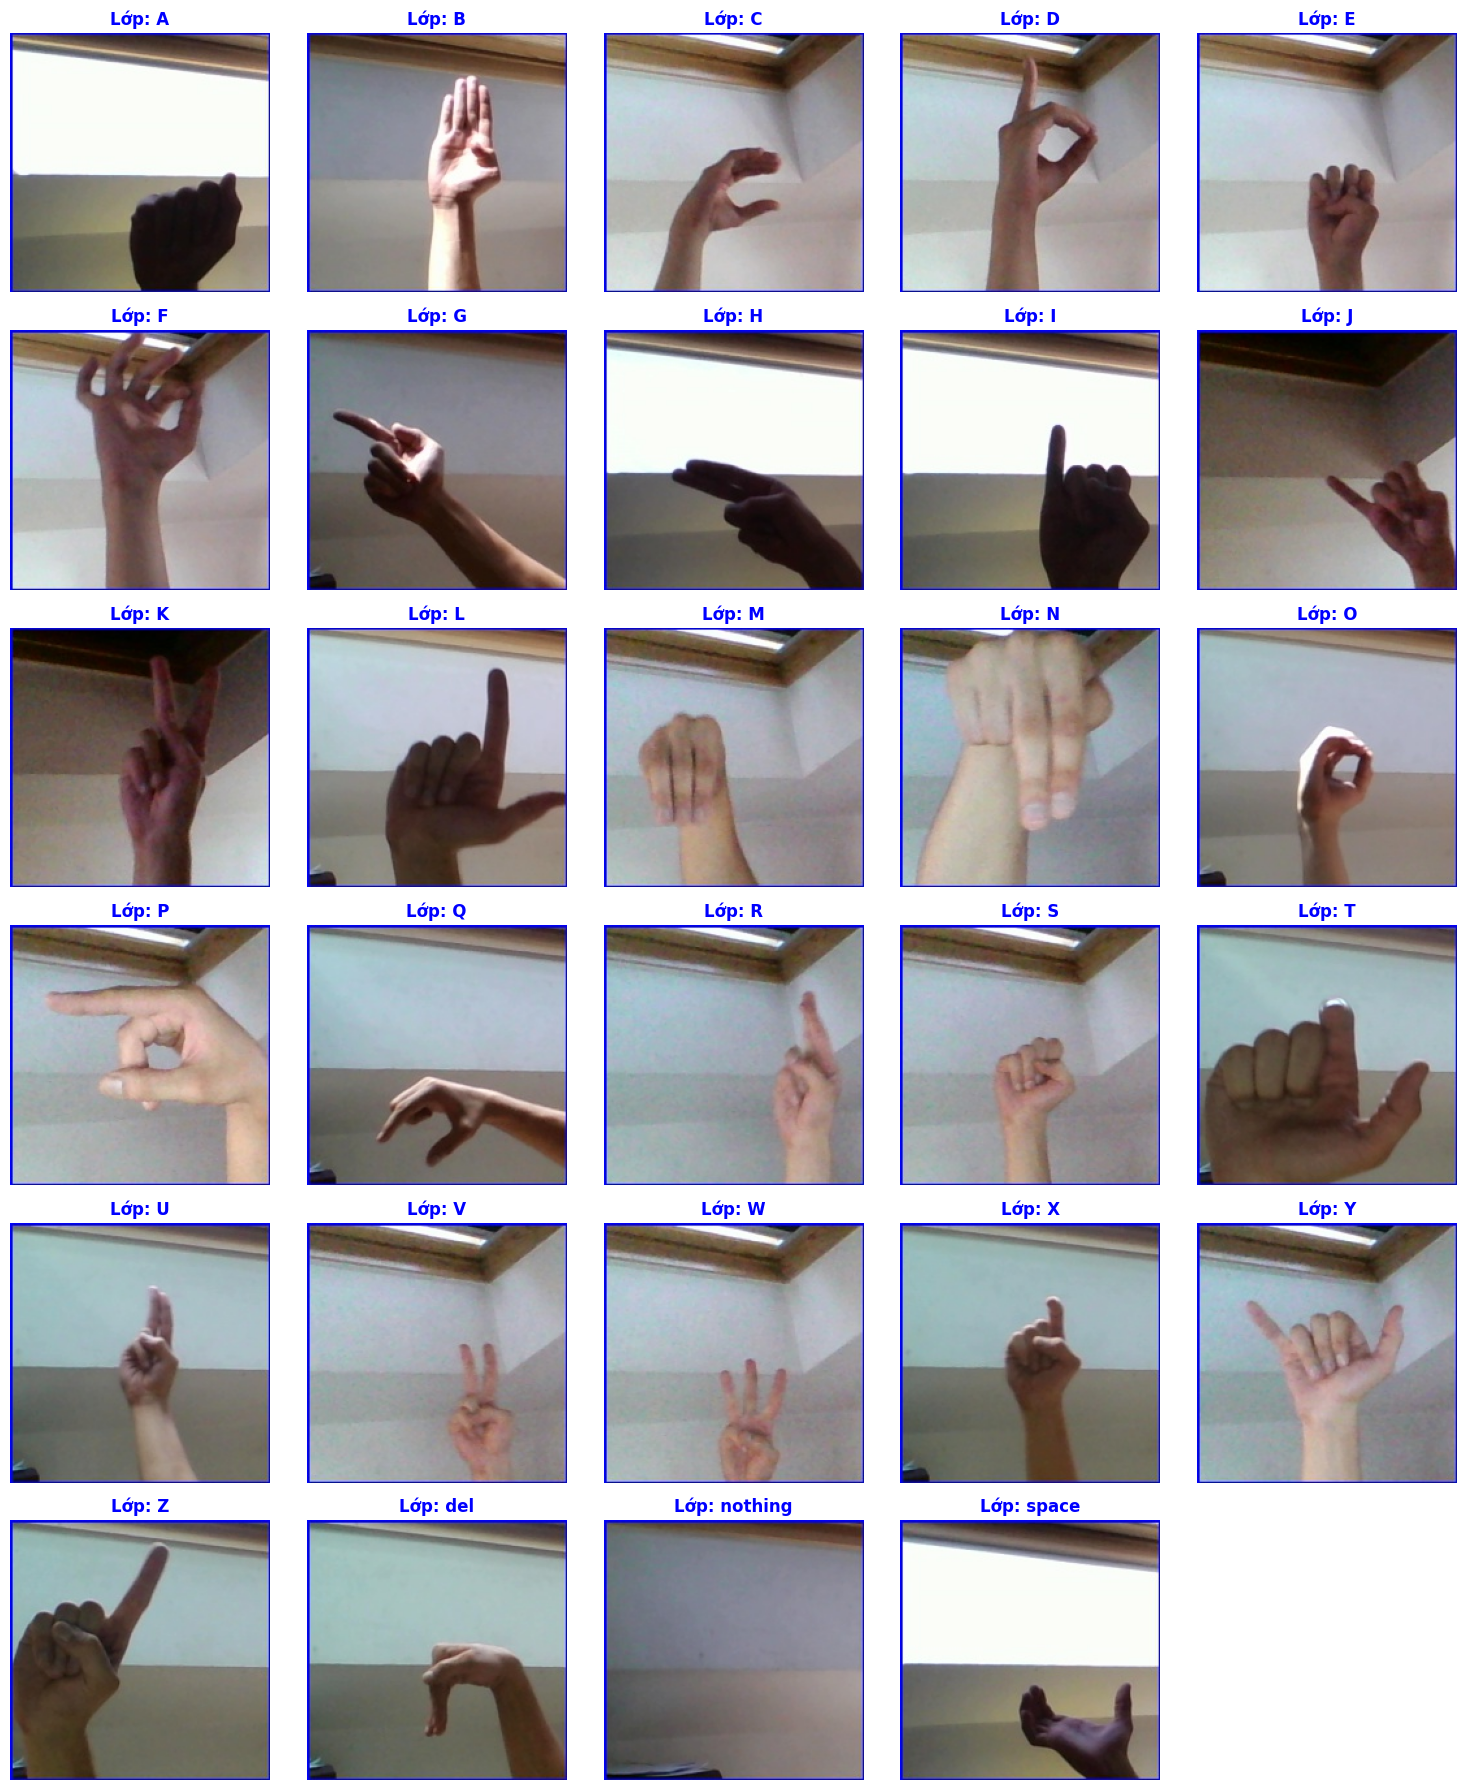

In [6]:
import os
import random
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img

# Đường dẫn tới thư mục tập Test sau khi đã chia
test_dir = "asl_split/test"

# Lấy danh sách các lớp và sắp xếp theo thứ tự bảng chữ cái (A-Z trước, sau đó là del, nothing, space)
classes = sorted(os.listdir(test_dir))

# Khởi tạo khung vẽ kích thước 6 hàng x 5 cột (chứa tối đa 30 ảnh)
fig, axes = plt.subplots(6, 5, figsize=(15, 18))
axes = axes.ravel()  # Trải phẳng ma trận ô vẽ thành danh sách 1 chiều để dễ duyệt

for i in range(30):
    # Ô thứ 30 sẽ bỏ trống vì chúng ta chỉ có 29 lớp
    if i >= len(classes):
        axes[i].axis('off')
        continue

    c = classes[i]
    class_path = os.path.join(test_dir, c)

    # Lấy ngẫu nhiên 1 ảnh trong thư mục Test của lớp đó
    img_list = os.listdir(class_path)
    if len(img_list) > 0:
        img_name = random.choice(img_list)
        img_path = os.path.join(class_path, img_name)

        # Load ảnh
        img = load_img(img_path)

        # Vẽ ảnh lên ô tương ứng
        axes[i].imshow(img)
        axes[i].set_title(f"Lớp: {c}", fontsize=12, fontweight='bold', color='blue')
    else:
        axes[i].text(0.5, 0.5, "Trống", ha='center', va='center')

    axes[i].axis('off') # Tắt trục tọa độ cho ảnh đẹp sạch sẽ

# Cân chỉnh khoảng cách giữa các ô vẽ
plt.tight_layout()

# Lưu bảng ảnh này thành file để chèn vào báo cáo BTL
os.makedirs("models", exist_ok=True)
plt.savefig("models/test_dataset_grid.png", dpi=300)
print("Đã hiển thị và lưu bảng ảnh tập Test tại: models/test_dataset_grid.png")
plt.show()

In [7]:
history_base = base_model.fit(
    train_generator,
    epochs=12,
    validation_data=val_generator
)

Epoch 1/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 81s 35ms/step - accuracy: 0.7742 - loss: 0.7393 - val_accuracy: 0.9466 - val_loss: 0.1673
Epoch 2/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 72s 33ms/step - accuracy: 0.9682 - loss: 0.0995 - val_accuracy: 0.9587 - val_loss: 0.1188
Epoch 3/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 72s 33ms/step - accuracy: 0.9832 - loss: 0.0543 - val_accuracy: 0.9864 - val_loss: 0.0451
Epoch 4/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 71s 32ms/step - accuracy: 0.9881 - loss: 0.0396 - val_accuracy: 0.9831 - val_loss: 0.0651
Epoch 5/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 71s 32ms/step - accuracy: 0.9917 - loss: 0.0271 - val_accuracy: 0.9879 - val_loss: 0.0411
Epoch 6/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 70s 32ms/step - accuracy: 0.9926 - loss: 0.0233 - val_accuracy: 0.9862 - val_loss: 0.0457
Epoch 7/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 71s 33ms/step - accuracy: 0.9932 - loss: 0.0223 - val_accuracy: 0.9862 - val_loss: 0.0479
Epoch 8/12
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 72s 33ms/step - accuracy: 0.9949 -

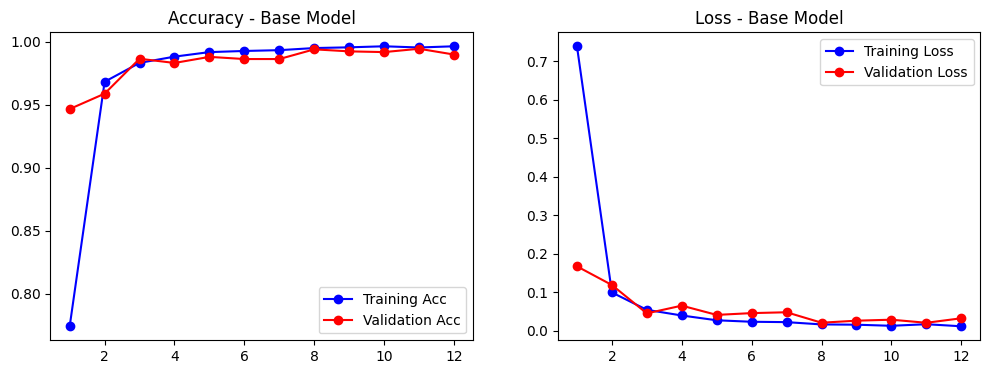

In [8]:
import matplotlib.pyplot as plt

def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 4))

    # Accuracy Chart
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'ro-', label='Validation Acc')
    plt.title(f'Accuracy - {title}')
    plt.legend()

    # Loss Chart
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    plt.title(f'Loss - {title}')
    plt.legend()

    plt.show()

plot_history(history_base, "Base Model")

In [9]:
train_datagen_augmented = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=False  # Không lật ảnh ngang vì tay trái/phải sẽ đổi nghĩa chữ cái
)

train_generator_aug = train_datagen_augmented.flow_from_directory(
    train_dir, target_size=(100, 100), batch_size=32, class_mode='categorical'
)

Found 69600 images belonging to 29 classes.


In [10]:
from tensorflow.keras.layers import Dropout, BatchNormalization

def build_improved_model():
    model = Sequential([
        # Khối CNN 1
        Conv2D(32, (3, 3), activation='relu', input_shape=(100, 100, 3)),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # Khối CNN 2
        Conv2D(64, (3, 3), activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # Phân loại
        Flatten(),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.4),
        Dense(len(classes), activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

improved_model = build_improved_model()

In [11]:
# Ô code 11 sửa đổi:
history_improved = improved_model.fit(
    train_generator_aug,
    epochs=18,
    steps_per_epoch=len(train_generator_aug),   # <-- KHAI BÁO RÕ SỐ BƯỚC TRAIN
    validation_data=val_generator,
    validation_steps=len(val_generator)         # <-- KHAI BÁO RÕ SỐ BƯỚC VAL
)

Epoch 1/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 268s 120ms/step - accuracy: 0.4320 - loss: 1.9048 - val_accuracy: 0.7532 - val_loss: 0.7959
Epoch 2/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 249s 114ms/step - accuracy: 0.7310 - loss: 0.8134 - val_accuracy: 0.8180 - val_loss: 0.5320
Epoch 3/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 254s 117ms/step - accuracy: 0.8069 - loss: 0.5723 - val_accuracy: 0.8545 - val_loss: 0.4351
Epoch 4/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 253s 116ms/step - accuracy: 0.8407 - loss: 0.4678 - val_accuracy: 0.7779 - val_loss: 0.6525
Epoch 5/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 253s 116ms/step - accuracy: 0.8648 - loss: 0.3968 - val_accuracy: 0.9410 - val_loss: 0.1858
Epoch 6/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 251s 115ms/step - accuracy: 0.8796 - loss: 0.3541 - val_accuracy: 0.9387 - val_loss: 0.1720
Epoch 7/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 252s 116ms/step - accuracy: 0.8879 - loss: 0.3313 - val_accuracy: 0.9731 - val_loss: 0.0888
Epoch 8/18
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 256s 118ms/step - ac

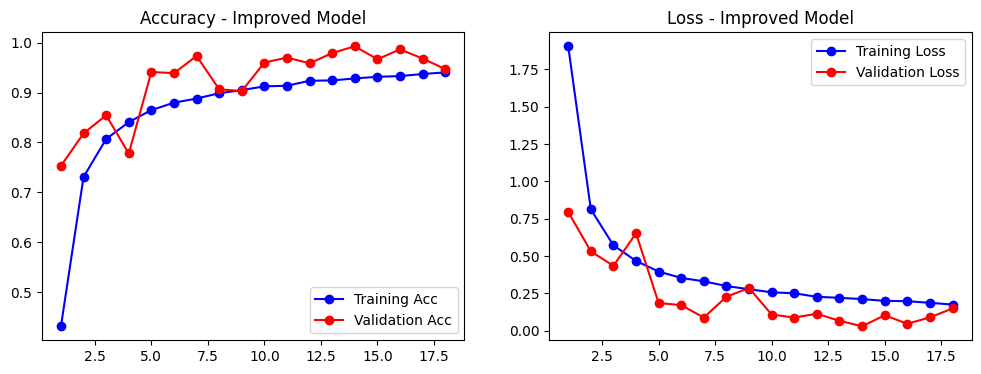

In [12]:
plot_history(history_improved, "Improved Model")

In [13]:
# Đánh giá 2 mô hình trên tập Test
loss_b, acc_b = base_model.evaluate(test_generator)
loss_i, acc_i = improved_model.evaluate(test_generator)

print("\n" + "="*20 + " BẢNG SO SÁNH KẾT QUẢ TẬP TEST " + "="*20)
print(f"Base Model     - Loss: {loss_b:.4f} | Accuracy: {acc_b*100:.2f}%")
print(f"Improved Model - Loss: {loss_i:.4f} | Accuracy: {acc_i*100:.2f}%")
print("="*71)

272/272 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.9910 - loss: 0.0240
272/272 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9431 - loss: 0.1573

==================== BẢNG SO SÁNH KẾT QUẢ TẬP TEST ====================
Base Model     - Loss: 0.0240 | Accuracy: 99.10%
Improved Model - Loss: 0.1573 | Accuracy: 94.31%


In [14]:
# Lưu mô hình
improved_model.save("asl_classifier.keras")

# Tải về máy tính cá nhân
from google.colab import files
files.download("asl_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>